Mounted at /content/drive

C3-28 | Experimental reference-surface learning and assessment
RUN: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-28_reference_shape_confidence_20261022T100842Z 
GPU: False 
No changes to prior checkpoints.
RGB stems: 998 raw depth stems: 998
Strict-quality reference pairs: train= 84 dev= 72
Skip audit: {('train', 'not_strict'): 212}
Epoch 01: train=0.3615 validation=0.1942
Epoch 05: train=0.3261 validation=0.1812
Epoch 10: train=0.3453 validation=0.1732
Epoch 15: train=0.3474 validation=0.1726
Epoch 20: train=0.3328 validation=0.1721
Epoch 25: train=0.3544 validation=0.1632
Epoch 30: train=0.3565 validation=0.1644
Epoch 35: train=0.3401 validation=0.1609
Epoch 40: train=0.3778 validation=0.1714

FROZEN DEVELOPMENT REFERENCE SHAPE MAE (RAW): {'trained_ref_mae_raw': 43.2821299235026, 'flat_mae_raw': 59.21562190188302, 'train_mean_mae_raw': 42.75877335336473}
Improvement gate selected on intra-training validation only: True (de

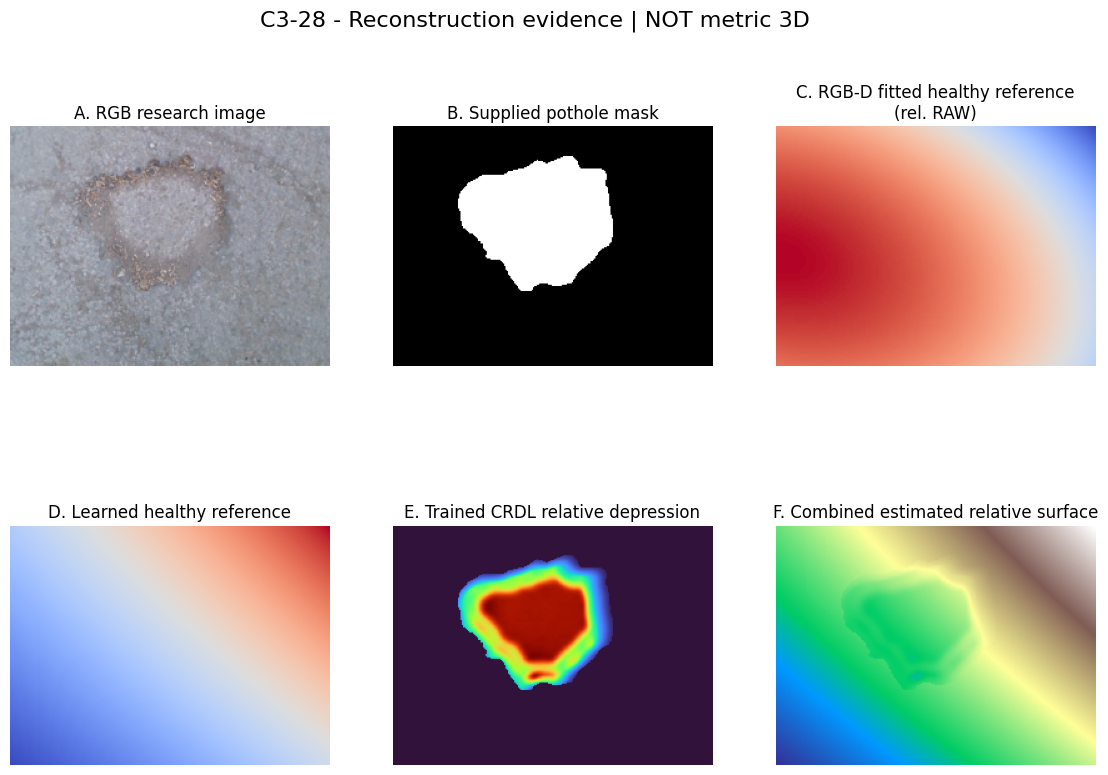

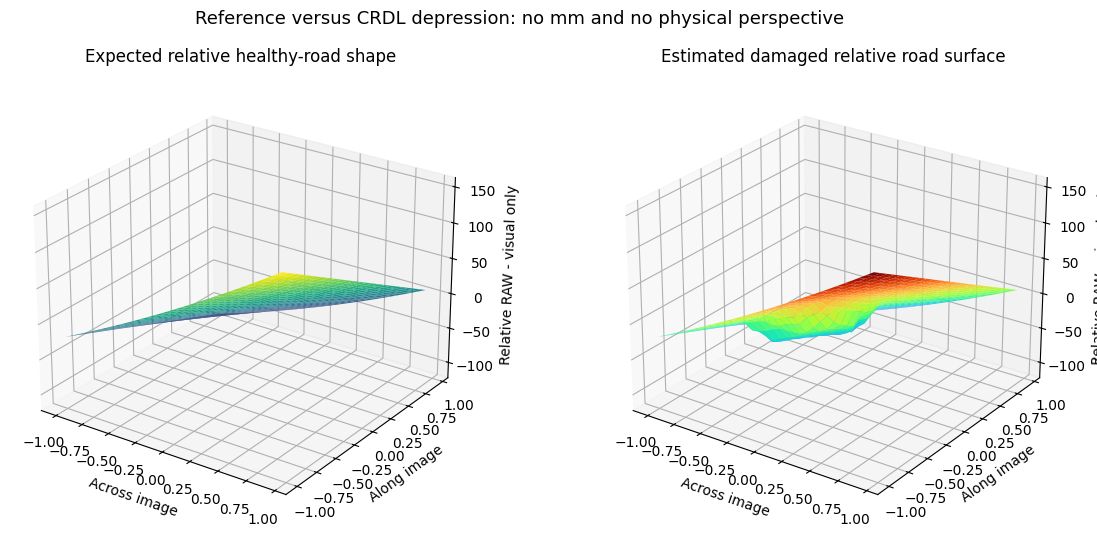

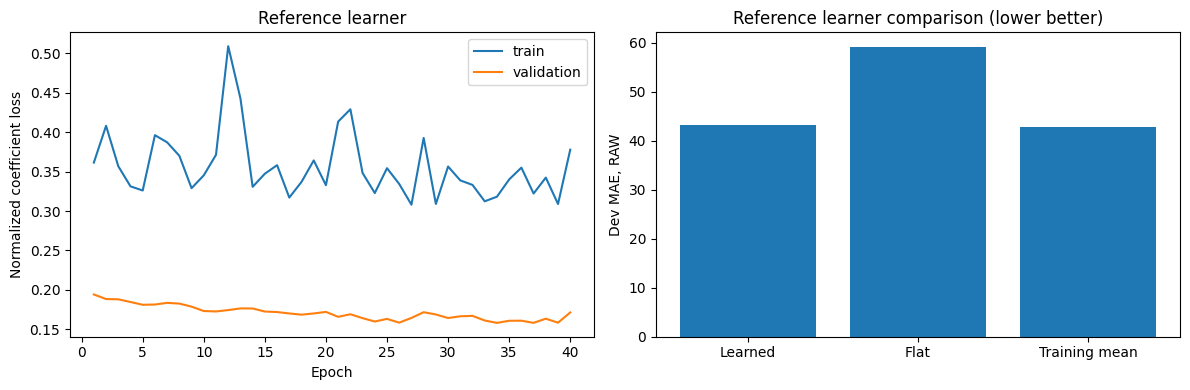


C3-28 COMPLETE: experimental auxiliary reference learner trained and evaluated.
Existing CRDL and severity models unchanged.
No physical calibration established.
Model improvement gate: True
UI source: actual reconstructed images and internal_assessment.json; ONLY PDF for public download.
PDF: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-28_reference_shape_confidence_20261022T100842Z/C3-28_Research_Reconstruction_and_Assessment.pdf
RUN: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-28_reference_shape_confidence_20261022T100842Z


In [1]:
# C3-28 | Evidence-aware healthy-road reference learning and severity profile
# RUN IN GOOGLE COLAB (GPU optional), Google Drive paths from the existing CRDL project.
# RESEARCH EXPERIMENT: relative RAW units only; no metric or scene-independent claims.
import os, sys, json, math, time, random, hashlib, warnings, importlib.util
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import binary_dilation
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
except ImportError:
    pass

# ---------------------- SECTION 0 | Provenance -----------------------------
SEED=20261022
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
ROOT=Path('/content/drive/MyDrive/crdl_experiments/component3_fresh_v1')
DATA=Path('/content/drive/MyDrive/manushi_research_data/pothrgbd/PData-main')
TRAIN=ROOT/'06_geometry_targets'/'C3-11_section04_weighted_feasibility_20261021T050356Z_383980'
# Locate source folder by an exact known name, even when organizational parent changes.
if not TRAIN.is_dir():
    matches=list(ROOT.rglob('C3-11_section04_weighted_feasibility_20261021T050356Z_383980'))
    TRAIN=matches[0] if matches else TRAIN
DEV=ROOT/'07_evaluation'/'C3-13_section01_frozen_dev_20261021T063918Z_9fee2e'
BUNDLE=ROOT/'08_integration'/'C3-14_provisional_component3_20261021T065928Z_c144de'
VIS=ROOT/'05_training_runs'/'C3-22_visual_severity_20261022T064701Z'
RUN=ROOT/'05_training_runs'/f'C3-28_reference_shape_confidence_{time.strftime("%Y%m%dT%H%M%SZ",time.gmtime())}'
RUN.mkdir(parents=True,exist_ok=False)
for folder in [DATA/'images',DATA/'depths',TRAIN/'targets',TRAIN/'cases',DEV/'cases',DEV/'strict_targets',BUNDLE,VIS]:
    if not folder.exists(): raise FileNotFoundError(f'Missing existing path: {folder}')
print('\nC3-28 | Experimental reference-surface learning and assessment')
print('RUN:',RUN,'\nGPU:',torch.cuda.is_available(),'\nNo changes to prior checkpoints.')
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'

# ---------------------- SECTION 1 | Paired data audit -----------------------
IMG_FILES={};DEP_FILES={}
for p in (DATA/'images').glob('*'):
    if p.suffix.lower() in {'.jpg','.jpeg','.png'}:
        IMG_FILES.setdefault(p.name[:15],[]).append(p)
for p in (DATA/'depths').glob('*.npy'):
    DEP_FILES.setdefault(p.name[:15],[]).append(p)
print('RGB stems:',len(IMG_FILES),'raw depth stems:',len(DEP_FILES))

# Fit a healthy-road reference from ONLY the visible healthy ring around the mask.
# Candidate 1: inverse-depth plane, Candidate 2: inverse-depth quadratic.
def coordinate_grid(h,w):
    yy,xx=np.mgrid[0:h,0:w]
    xx=(xx.astype('float64')-(w-1)/2)/max((w-1)/2,1)
    yy=(yy.astype('float64')-(h-1)/2)/max((h-1)/2,1)
    return xx,yy

def basis_grid(x,y,kind):
    if kind=='plane': return np.stack([np.ones_like(x),x,y],axis=-1)
    return np.stack([np.ones_like(x),x,y,x*x,y*y,x*y],axis=-1)

def fit_reference(depth,mask,seed=0):
    z=np.asarray(depth,dtype='float64'); m=np.asarray(mask,dtype=bool)
    if z.ndim!=2 or m.shape!=z.shape: return None
    h,w=z.shape;x,y=coordinate_grid(h,w)
    ring=binary_dilation(m,iterations=31)&(~binary_dilation(m,iterations=5))
    valid=ring&np.isfinite(z)&(z>0)
    if valid.sum()<650: return None
    med=np.median(z[valid]);lo,hi=np.quantile(z[valid],[0.015,0.985])
    valid &= (z>=max(lo,med*0.3))&(z<=min(hi,med*3))
    if valid.sum()<600: return None
    rows=np.flatnonzero(valid.ravel());rng=np.random.default_rng(seed)
    if len(rows)>12000:rows=rng.choice(rows,12000,replace=False)
    rng.shuffle(rows);nfit=int(0.80*len(rows));ia=rows[:nfit];ib=rows[nfit:]
    inverse_scale=np.median(1/z.ravel()[ia]); inv=(1/z.ravel()[ia])/inverse_scale
    candidates=[]
    for kind in ['plane','quadratic']:
        M=basis_grid(x,y,kind).reshape(-1,3 if kind=='plane' else 6)
        A=M[ia]; b=inv.copy(); p=np.linalg.lstsq(A,b,rcond=None)[0]
        for _ in range(6):
            residual=b-A@p;mad=1.4826*np.median(np.abs(residual-np.median(residual)))+1e-7
            weights=np.clip(1.345*mad/(np.abs(residual)+1e-9),0.04,1)
            p=np.linalg.lstsq(A*weights[:,None]**0.5,b*weights**0.5,rcond=None)[0]
        pred_v=M[ib]@p
        if np.any(pred_v<=0):continue
        pred_z=(pred_v*inverse_scale)**(-1)
        error=np.median(np.abs(pred_z-z.ravel()[ib]))
        candidates.append((error*(1.03 if kind=='quadratic' else 1.0),kind,p,M))
    if not candidates:return None
    _,kind,p,M=min(candidates,key=lambda t:t[0]);mapped=(M@p)*inverse_scale
    if (mapped<=0).any():return None
    ref=(1/mapped).reshape(h,w)
    central=float(ref[h//2,w//2]); rel=(ref-central).astype('float32')
    # Model coefficients in an image-centered polynomial, in unverified RAW units.
    B=np.stack([x,y,x*x,y*y,x*y],axis=-1).reshape(-1,5)
    c=np.linalg.lstsq(B[::12],rel.ravel()[::12],rcond=None)[0].astype('float32')
    return dict(ref=ref.astype('float32'),rel=rel,coefficients=c,kind=kind,
                road_support=int(valid.sum()),road_fit_mae_raw=float(np.median(np.abs(ref[valid]-z[valid]))),
                origin_raw=central)

def image_array(path,hw):
    h,w=hw
    return np.asarray(Image.open(path).convert('RGB').resize((w,h),Image.Resampling.BILINEAR),dtype=np.uint8)

def make_example(path,source,require_strict=True):
    sample_id=path.name[:15]
    case_path=(TRAIN if source=='train' else DEV)/'cases'/f'{sample_id}.json'
    if not case_path.exists(): return None,'missing_case'
    case=json.loads(case_path.read_text())
    if require_strict and case.get('tier')!='STRICT':return None,'not_strict'
    if sample_id not in IMG_FILES or sample_id not in DEP_FILES:return None,'missing_pair'
    zfile=DEP_FILES[sample_id][0];imgfile=IMG_FILES[sample_id][0]
    try:
        z=np.load(zfile,allow_pickle=False)
        if z.ndim==3 and z.shape[-1]==1:z=z[...,0]
        if z.ndim!=2:return None,'depth_shape'
        a=np.load(path,allow_pickle=False);mask=a['pothole_mask']>0
        h,w=mask.shape
        if z.shape!=(h,w):
            z=np.asarray(Image.fromarray(z.astype('float32')).resize((w,h),Image.Resampling.NEAREST))
        rgb=image_array(imgfile,(h,w))
        fit=fit_reference(z,mask,seed=int(hashlib.sha256(sample_id.encode()).hexdigest()[:8],16))
        if fit is None:return None,'reference_fit_failed'
        # Display/learning at consistent model input resolution.
        smallrgb=np.asarray(Image.fromarray(rgb).resize((128,96),Image.Resampling.BILINEAR))
        smallmask=np.asarray(Image.fromarray((mask*255).astype('uint8')).resize((128,96),Image.Resampling.NEAREST))>0
        xx,yy=coordinate_grid(96,128)
        c=fit['coefficients']; normal=(c[0]*xx+c[1]*yy+c[2]*xx*xx+c[3]*yy*yy+c[4]*xx*yy).astype('float32')
        return dict(id=sample_id,rgb=rgb,mask=mask,smallrgb=smallrgb,smallmask=smallmask,
                    c=c,reference=normal,observed=z.astype('float32'),fit=fit,source=source,
                    source_img=str(imgfile),source_depth=str(zfile)),None
    except Exception as e:
        return None,'load_error_'+type(e).__name__

trains=[];devs=[];reason=Counter()
for src,folder,arr in [('train',TRAIN/'targets',trains),('dev',DEV/'strict_targets',devs)]:
    pattern='*_axial_raw.npz' if src=='train' else '*_target.npz'
    for p in sorted(folder.glob(pattern)):
        item,error=make_example(p,src)
        if item: arr.append(item)
        else: reason[(src,error)]+=1
print('Strict-quality reference pairs: train=',len(trains),'dev=',len(devs))
print('Skip audit:',dict(reason))
if len(trains)<25 or len(devs)<12:
    raise RuntimeError('Too few strict-quality matched RGB-D cases for the proposed experiment. Verify source alignment and paths, do not fabricate pairs.')

# ---------------------- SECTION 2 | Train the auxiliary model --------------
# This model learns image-centered relative healthy-road SHAPE, not absolute 3D height.
# It does not replace your existing primary trained CRDL depression predictor.
shuffled=np.random.default_rng(SEED).permutation(len(trains))
cut=max(10,int(0.8*len(trains)));trainids=shuffled[:cut];valids=shuffled[cut:]
trainarr=[trains[i] for i in trainids];valarr=[trains[i] for i in valids]
coef=np.stack([r['c'] for r in trainarr]);mu=coef.mean(axis=0);sd=np.maximum(coef.std(axis=0),0.5)
class RefDataset(Dataset):
    def __init__(self,items):self.items=items
    def __len__(self):return len(self.items)
    def __getitem__(self,i):
        a=self.items[i];rgb=a['smallrgb'].astype('float32').transpose(2,0,1)/255
        mask=a['smallmask'].astype('float32')[None]
        return torch.from_numpy(np.concatenate([rgb,mask])).float(),torch.from_numpy(((a['c']-mu)/sd).astype('float32'))
class HealthyRoadShapeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(4,16,5,stride=2,padding=2),nn.ReLU(),
                                   nn.Conv2d(16,32,3,stride=2,padding=1),nn.ReLU(),
                                   nn.Conv2d(32,48,3,stride=2,padding=1),nn.ReLU(),
                                   nn.Conv2d(48,64,3,stride=2,padding=1),nn.ReLU(),
                                   nn.AdaptiveAvgPool2d(1),nn.Flatten())
        self.head=nn.Sequential(nn.Linear(64,64),nn.ReLU(),nn.Linear(64,5))
    def forward(self,x):return self.head(self.features(x))
train_loader=DataLoader(RefDataset(trainarr),batch_size=16,shuffle=True,num_workers=0)
val_loader=DataLoader(RefDataset(valarr),batch_size=32,shuffle=False,num_workers=0)
model=HealthyRoadShapeNet().to(DEVICE);opt=torch.optim.AdamW(model.parameters(),lr=0.001,weight_decay=0.01)
losfn=nn.SmoothL1Loss();best=np.inf;best_epoch=0;history=[];best_weights=None;stale=0
for epoch in range(1,41):
    model.train();losses=[]
    for x,y in train_loader:
        x=x.to(DEVICE);y=y.to(DEVICE);opt.zero_grad()
        loss=losfn(model(x),y);loss.backward();opt.step();losses.append(float(loss.detach().cpu()))
    model.eval();val_losses=[]
    with torch.no_grad():
        for x,y in val_loader:val_losses.append(float(losfn(model(x.to(DEVICE)),y.to(DEVICE)).cpu()))
    row={'epoch':epoch,'train_loss':float(np.mean(losses)),'val_loss':float(np.mean(val_losses))}
    history.append(row)
    if row['val_loss']<best-0.0001:
        best=row['val_loss'];best_epoch=epoch;stale=0
        best_weights={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    else:stale+=1
    if epoch%5==0 or epoch==1:print(f'Epoch {epoch:02d}: train={row["train_loss"]:.4f} validation={row["val_loss"]:.4f}')
    if stale>=9:break
model.load_state_dict(best_weights);model.eval();pd.DataFrame(history).to_csv(RUN/'reference_training_history.csv',index=False)

# ---------------------- SECTION 3 | Baselines and gated evaluation ---------
xx,yy=coordinate_grid(96,128)
B=np.stack([xx,yy,xx*xx,yy*yy,xx*yy],axis=-1).astype('float32')
def surface(c):return np.einsum('ijk,k->ij',B,np.asarray(c,dtype='float32'))
def infer_coeff(a):
    x,_=RefDataset([a])[0]
    with torch.no_grad():v=model(x[None].to(DEVICE))[0].cpu().numpy()
    return v*sd+mu

def eval_set(items):
    out=[]
    for a in items:
        truth=surface(a['c']);cur=infer_coeff(a)
        err=lambda c:float(np.mean(np.abs(surface(c)-truth)))
        out.append(dict(id=a['id'],trained_ref_mae_raw=err(cur),flat_mae_raw=err(np.zeros(5)),
                        train_mean_mae_raw=err(mu),road_fit_mae_raw=a['fit']['road_fit_mae_raw'],
                        candidate=a['fit']['kind']))
    return pd.DataFrame(out)
valresult=eval_set(valarr);auditresult=eval_set(devs)
valresult.to_csv(RUN/'intra_training_val_reference.csv',index=False)
auditresult.to_csv(RUN/'frozen_dev_reference_audit.csv',index=False)
performance={name:float(auditresult[name].mean()) for name in ['trained_ref_mae_raw','flat_mae_raw','train_mean_mae_raw']}
val_perf={k:float(valresult[k].mean()) for k in ['trained_ref_mae_raw','flat_mae_raw','train_mean_mae_raw']}
ref_gate=val_perf['trained_ref_mae_raw'] < min(val_perf['flat_mae_raw'],val_perf['train_mean_mae_raw'])
print('\nFROZEN DEVELOPMENT REFERENCE SHAPE MAE (RAW):',performance)
print('Improvement gate selected on intra-training validation only:',ref_gate,'(deployment NOT authorized)')
ck={'state_dict':best_weights,'mu':mu.tolist(),'sd':sd.tolist(),'arch':'HealthyRoadShapeNet/v1',
    'basis':['x','y','x2','y2','xy'],'native_hw':[96,128],
    'units':'UNVERIFIED_RAW_CAMERA_AXIAL_UNITS','best_epoch':best_epoch}
torch.save(ck,RUN/'healthy_road_relative_shape_model.pt')
reload=HealthyRoadShapeNet();reload.load_state_dict(torch.load(RUN/'healthy_road_relative_shape_model.pt',map_location='cpu',weights_only=True)['state_dict']);reload.eval()
with torch.no_grad():
    xt,_=RefDataset([devs[0]])[0];assert np.allclose(reload(xt[None]).numpy(),model(xt[None].to(DEVICE)).cpu().numpy(),atol=1e-4)
print('Checkpoint cold-load and identical prediction: PASS')

# ---------------------- SECTION 4 | Existing CRDL uncertainty -------------
# Calibrate an *experimental D95 RAW absolute-error tolerance* using saved dev errors.
# Since CRDL was already selected on these development results, this is NOT a clean
# untouched calibration sample and does NOT establish field confidence or coverage.
records=[]
for p in sorted((DEV/'cases').glob('*.json')):
    try:
        j=json.loads(p.read_text())
        if j.get('tier')!='STRICT':continue
        score=j.get('scores',{}).get('DIRECT_RGB_MASK',{})
        e=score.get('d95_abs_raw')
        if e is not None and np.isfinite(float(e)):
            records.append(dict(id=j['sample_id'],error_raw=float(e),burst=j.get('burst','UNKNOWN')))
    except Exception:pass
if len(records)<20:raise RuntimeError('Insufficient frozen development D95 errors for a reliability diagnostic.')
records=sorted(records,key=lambda r:r['id'])
pick=np.random.default_rng(SEED).permutation(len(records));ncal=int(len(records)*0.65)
cal=[records[i]['error_raw'] for i in pick[:ncal]];eva=[records[i]['error_raw'] for i in pick[ncal:]]
rank=min(len(cal),math.ceil((len(cal)+1)*0.9));q90=float(np.sort(cal)[rank-1]);coverage=float((np.asarray(eva)<=q90).mean())
cal_report={'label':'EXPLORATORY_DEVELOPMENT_ONLY','quantity':'D95_ABSOLUTE_RAW_ERROR',
            'q90_raw':q90,'calibration_n':len(cal),'audit_n':len(eva),'audit_coverage':coverage,
            'nominal_target':0.90,'physical_mm_covered':False,
            'notes':'CRDL model was selected using related development evidence; temporal/site exchangeability unverified. Not a deployable 90% accuracy claim.'}
(RUN/'research_raw_uncertainty.json').write_text(json.dumps(cal_report,indent=2))
print('\nExploratory D95 RAW absolute-error threshold:',round(q90,2),'on',len(cal),'calibration examples')
print('Development audit coverage:',round(coverage,3),'on',len(eva),'examples; NOT calibrated physical confidence.')

# ---------------------- SECTION 5 | Same-image dual-model demonstration ----
# Uses already trained checkpoint; no model retraining or invented severity.
sample=devs[0]
assessment={'sample_id':sample['id'],'rgb_path':sample['source_img'],
            'confidence_message':'Experimental image-based findings; field inspection required for physical severity.',
            'physical_depth_mm':None,'physical_severity':None,
            'ref_model_gate':ref_gate,'reference_method':'Learned relative healthy-road shape (experimental)'}
refcoef=infer_coeff(sample) if ref_gate else np.zeros(5,dtype='float32')
refmap=surface(refcoef)
assessment['relative_reference_approved_for_experimental_visual']=bool(ref_gate)

# The CRDL bundle is loaded from its unchanged frozen checkpoint.
sys.path.insert(0,str(BUNDLE))
try:
    from component3_service import Component3Prototype
    c3=Component3Prototype(BUNDLE,device=DEVICE)
    pred=c3.predict(sample['rgb'],sample['mask'],include_map=True)
    crdl_raw=np.asarray(pred['raw_axial_depression_map'],dtype='float32')
    d95=float(pred['geometry_raw']['d95_raw'])
    assessment['predicted_d95_raw']=d95
    assessment['crdl_version']=c3.meta['bundle_version']
except Exception as ex:
    crdl_raw=None;assessment['crdl_error']=repr(ex)

try:
    sys.path.insert(0,str(VIS))
    from visual_severity_inference import VisualSeverityClassifier
    ys,xs=np.nonzero(sample['mask'])
    # Native mask coordinates must be mapped to original RGB dimensions.
    H,W=sample['rgb'].shape[:2]
    bbox=[max(0,int(xs.min()*W/sample['mask'].shape[1])),
          max(0,int(ys.min()*H/sample['mask'].shape[0])),
          min(W,int((xs.max()+1)*W/sample['mask'].shape[1])),
          min(H,int((ys.max()+1)*H/sample['mask'].shape[0]))]
    visual=VisualSeverityClassifier(VIS,device=DEVICE).predict(sample['rgb'],bbox)
    assessment['visual_severity']=visual['visual_severity'];assessment['visual_review_required']=visual['review_required']
    assessment['severity_kind']=visual['severity_kind']
    assessment['visual_model_version']=visual['model_version']
except Exception as ex:assessment['visual_model_error']=repr(ex)

# ---------------------- SECTION 5b | Backend package ------------------------
REFERENCE_INFERENCE_SRC='"""C3-28 experimental relative healthy-road reference prediction, NOT metric geometry.\n\nUse alongside, not instead of, the frozen primary CRDL pothole depression model.\n"""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport torch\nfrom torch import nn\nfrom PIL import Image\n\nclass HealthyRoadShapeNet(nn.Module):\n    def __init__(self):\n        super().__init__()\n        self.features=nn.Sequential(nn.Conv2d(4,16,5,stride=2,padding=2),nn.ReLU(),\n            nn.Conv2d(16,32,3,stride=2,padding=1),nn.ReLU(),\n            nn.Conv2d(32,48,3,stride=2,padding=1),nn.ReLU(),\n            nn.Conv2d(48,64,3,stride=2,padding=1),nn.ReLU(),\n            nn.AdaptiveAvgPool2d(1),nn.Flatten())\n        self.head=nn.Sequential(nn.Linear(64,64),nn.ReLU(),nn.Linear(64,5))\n    def forward(self,x):return self.head(self.features(x))\n\nclass RelativeHealthyRoadReference:\n    def __init__(self, bundle, device=\'cpu\'):\n        root=Path(bundle)\n        ck=torch.load(root/\'healthy_road_relative_shape_model.pt\',map_location=\'cpu\',weights_only=True)\n        self.model=HealthyRoadShapeNet().to(device).eval()\n        self.model.load_state_dict(ck[\'state_dict\'],strict=True)\n        self.mu=np.asarray(ck[\'mu\'],dtype=\'float32\')\n        self.sd=np.asarray(ck[\'sd\'],dtype=\'float32\')\n        self.device=device\n    def predict(self,rgb_uint8,mask):\n        rgb=np.asarray(rgb_uint8);m=np.asarray(mask)\n        if rgb.ndim!=3 or rgb.shape[-1]!=3 or rgb.dtype!=np.uint8:\n            raise ValueError(\'Expected uint8 RGB image HxWx3\')\n        if m.shape!=rgb.shape[:2] or not np.asarray(m>0).any():\n            raise ValueError(\'Aligned nonempty binary pothole mask required\')\n        arr=np.asarray(Image.fromarray(rgb).resize((128,96),Image.Resampling.BILINEAR),dtype=\'float32\').transpose(2,0,1)/255\n        msmall=np.asarray(Image.fromarray((m>0).astype(\'uint8\')*255).resize((128,96),Image.Resampling.NEAREST))>0\n        x=torch.from_numpy(np.concatenate([arr,msmall[None].astype(\'float32\')],axis=0)).unsqueeze(0).to(self.device)\n        with torch.inference_mode():\n            coeff=self.model(x)[0].cpu().numpy()*self.sd+self.mu\n        yy,xx=np.mgrid[:96,:128]\n        xx=(xx-(128-1)/2)/((128-1)/2)\n        yy=(yy-(96-1)/2)/((96-1)/2)\n        surface=coeff[0]*xx+coeff[1]*yy+coeff[2]*xx*xx+coeff[3]*yy*yy+coeff[4]*xx*yy\n        return {\'relative_healthy_surface_raw\':surface.astype(\'float32\'),\n                \'native_hw\':[96,128],\n                \'units\':\'UNVERIFIED_RAW_RELATIVE_CAMERA_AXIS\',\n                \'is_metric_3d\':False,\n                \'model_kind\':\'EXPERIMENTAL_LEARNED_REFERENCE_SHAPE\',\n                \'horizontal_coordinates\':\'image_normalized\',\n                \'vertical_reference\':\'arbitrary image-centered zero\'}\n'
(RUN/'C3_28_reference_inference.py').write_text(REFERENCE_INFERENCE_SRC)
contract={'version':'C3-28.0.0-experimental','input':{'rgb':'uint8 HxWx3','pothole_mask':'H x W aligned binary'},
 'output':{'relative_healthy_surface_raw':'float32[96,128]','units':'UNVERIFIED_RAW_RELATIVE_CAMERA_AXIS','is_metric_3d':False},
 'deployment_requirement':'Do not enable learned reference unless validated and baseline improvement gate passed; primary CRDL unchanged'}
(RUN/'api_contract.json').write_text(json.dumps(contract,indent=2))
(RUN/'calibration_and_units_evidence.json').write_text(json.dumps({'raw_depth_scale_certified':False,
 'road_frame_normal_verified':False,'physical_spot_check_verified':False,
 'qualified_metric_geometry':False,'confidence_caveat':'Raw tolerance is only an exploratory development-set statistic'},indent=2))
(RUN/'severity_profile_policy.json').write_text(json.dumps({'predicted_visual_severity':'C3-22 experimental classifier; no physical severity',
 'relative_geometry':'C3-14 trained CRDL RAW and C3-28 reference visualization',
 'physical_pothole_severity':'C3-20 field policy ONLY with independently measured eligible physical depth',
 'confidence_percent':None,'uncalibrated_scores_not_probability':True,
 'pdf_only_user_download':True},indent=2))
# New cold-load of new inference module, not just the training-time class.
spec=importlib.util.spec_from_file_location('c328_recon',RUN/'C3_28_reference_inference.py')
loaded=importlib.util.module_from_spec(spec);spec.loader.exec_module(loaded)
new_service=loaded.RelativeHealthyRoadReference(RUN,device='cpu')
smoke=new_service.predict(devs[0]['rgb'],devs[0]['mask'])
assert smoke['relative_healthy_surface_raw'].shape==(96,128)
assert np.isfinite(smoke['relative_healthy_surface_raw']).all()
(RUN/'cold_load_smoke.json').write_text(json.dumps({'status':'PASS','reference_shape':[96,128],
 'physical_metric_claims':False},indent=2))
print('Reconstruction backend service cold-load smoke: PASS')

# ---------------------- SECTION 6 | Visual evidence and PDF-only report ----
# These visuals are research demonstration artifacts; the frontend should
# render these concepts itself and only offer PDF as a user export.
fig=plt.figure(figsize=(14,9));gs=fig.add_gridspec(2,3,hspace=0.36,wspace=0.20)
ax=fig.add_subplot(gs[0,0]);ax.imshow(sample['rgb']);ax.set_title('A. RGB research image');ax.axis('off')
ax=fig.add_subplot(gs[0,1]);ax.imshow(sample['mask'],cmap='gray');ax.set_title('B. Supplied pothole mask');ax.axis('off')
ax=fig.add_subplot(gs[0,2]);ax.imshow(surface(sample['c']),cmap='coolwarm');ax.set_title('C. RGB-D fitted healthy reference\n(rel. RAW)');ax.axis('off')
ax=fig.add_subplot(gs[1,0]);ax.imshow(refmap,cmap='coolwarm');ax.set_title('D. Learned healthy reference' if ref_gate else 'D. Flat reference fallback');ax.axis('off')
ax=fig.add_subplot(gs[1,1]);
if crdl_raw is not None:ax.imshow(crdl_raw,cmap='turbo')
else:ax.text(.5,.5,'CRDL unavailable',ha='center',va='center')
ax.set_title('E. Trained CRDL relative depression');ax.axis('off')
ax=fig.add_subplot(gs[1,2]);
if crdl_raw is not None:
    # Downsample reference field to CRDL's 192x256 (image-space only)
    rmap=np.asarray(Image.fromarray(refmap.astype('float32')).resize((256,192),Image.Resampling.BILINEAR))
    ax.imshow(rmap-crdl_raw,cmap='terrain');ax.set_title('F. Combined estimated relative surface')
else:ax.set_title('F. Combined unavailable')
ax.axis('off')
fig.suptitle('C3-28 - Reconstruction evidence | NOT metric 3D',fontsize=16)
fig.savefig(RUN/'reconstruction_six_stage.png',dpi=155,bbox_inches='tight');plt.show();plt.close(fig)

fig=plt.figure(figsize=(14,6));ax=fig.add_subplot(121,projection='3d');bx=fig.add_subplot(122,projection='3d')
# Visualization downsample for reasonable speed.
sl=slice(None,None,4);X,Y=coordinate_grid(96,128);Z=refmap
ax.plot_surface(X[sl,sl],Y[sl,sl],Z[sl,sl],cmap='viridis',linewidth=0,antialiased=True)
ax.set_title('Expected relative healthy-road shape')
if crdl_raw is not None:
    map96=np.asarray(Image.fromarray(crdl_raw).resize((128,96),Image.Resampling.BILINEAR))
    bx.plot_surface(X[sl,sl],Y[sl,sl],(Z-map96)[sl,sl],cmap='turbo',linewidth=0,antialiased=True)
bx.set_title('Estimated damaged relative road surface')
for a in [ax,bx]:a.set_xlabel('Across image');a.set_ylabel('Along image');a.set_zlabel('Relative RAW - visual only');a.view_init(25,-55)
fig.suptitle('Reference versus CRDL depression: no mm and no physical perspective',fontsize=13)
fig.savefig(RUN/'reference_vs_damaged_surface.png',dpi=155,bbox_inches='tight');plt.show();plt.close(fig)

fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot([h['epoch'] for h in history],[h['train_loss'] for h in history],label='train')
axs[0].plot([h['epoch'] for h in history],[h['val_loss'] for h in history],label='validation')
axs[0].set_title('Reference learner');axs[0].set_xlabel('Epoch');axs[0].set_ylabel('Normalized coefficient loss');axs[0].legend()
keys=['trained_ref_mae_raw','flat_mae_raw','train_mean_mae_raw']
axs[1].bar(['Learned','Flat','Training mean'],[performance[k] for k in keys]);axs[1].set_ylabel('Dev MAE, RAW');axs[1].set_title('Reference learner comparison (lower better)')
fig.tight_layout();fig.savefig(RUN/'reference_training_evidence.png',dpi=155);plt.show();plt.close(fig)

with PdfPages(RUN/'C3-28_Research_Reconstruction_and_Assessment.pdf') as pdf:
    for fname in ['reconstruction_six_stage.png','reference_vs_damaged_surface.png','reference_training_evidence.png']:
        f,a=plt.subplots(figsize=(12,8));a.imshow(Image.open(RUN/fname));a.axis('off');f.tight_layout();pdf.savefig(f);plt.close(f)
    f,a=plt.subplots(figsize=(11.7,8.3));a.axis('off')
    lines=[
        'C3-28 | Evidence-aware assessment: research summary',
        '',f'Sample: {sample["id"]}',
        f'Visual severity (C3-22): {assessment.get("visual_severity","Unavailable")}',
        f'CRDL relative D95: {assessment.get("predicted_d95_raw","Unavailable")} RAW',
        'Physical depth and FHWA severity: NOT DETERMINED',
        f'Learned-reference beats baseline (frozen development): {ref_gate}',
        f'Dev reference MAE (learned/flat): {performance["trained_ref_mae_raw"]:.2f}/{performance["flat_mae_raw"]:.2f} RAW',
        f'Exploratory D95 error band: +/- {q90:.2f} RAW, development-only',
        f'Empirical development-audit coverage: {coverage:.1%} ({len(eva)} cases)',
        '',
        'Limitations: inferred surface is not calibrated 3D geometry.',
        'Unverified raw units cannot be converted into millimeters.',
        'The selected development data are not a physically independent confidence test.',
        'Experimental visual severity is not an FHWA field-reference severity.',
        'A validated site-specific calibration and real ruler evidence remain required.'
    ]
    a.text(0.06,0.94,'\n'.join(lines),ha='left',va='top',fontsize=11,family='DejaVu Sans',linespacing=1.6)
    pdf.savefig(f);plt.close(f)

assessment['confidence']={'mode':'EXPLORATORY_DEV_RAW_TOLERANCE','q90_abs_d95_error_raw':q90,
                          'audit_coverage':coverage,'physical_accuracy_confidence_percent':None}
assessment['severity_profile']={'pothole_visual':assessment.get('visual_severity'),'physical':None,
                                'surface_shape_available':crdl_raw is not None,
                                'geometry_units':'UNVERIFIED_RAW','field_inspection_required':True}
(RUN/'internal_assessment.json').write_text(json.dumps(assessment,indent=2,default=str))
model_meta={'version':'C3-28.0.0-experimental','train_count':len(trainarr),'val_count':len(valarr),
            'frozen_dev_count':len(devs),'seed':SEED,'best_epoch':best_epoch,
            'model_passes_reference_baselines_on_dev':bool(ref_gate),
            'raw_coordinate_only':True,'real_metric_validation':False,
            'independent_scene_generalization':False,'physical_severity_from_model':False,
            'training_source':'STRICT-quality PothRGBD paired RAW depth'}
(RUN/'reference_model_config.json').write_text(json.dumps(model_meta,indent=2))
with (RUN/'sha256_manifest.txt').open('w') as fo:
    for p in sorted(RUN.iterdir()):
        if p.is_file() and p.name!='sha256_manifest.txt':
            fo.write(hashlib.sha256(p.read_bytes()).hexdigest()+'  '+p.name+'\n')
print('\nC3-28 COMPLETE: experimental auxiliary reference learner trained and evaluated.')
print('Existing CRDL and severity models unchanged.')

print('No physical calibration established.')
print('Model improvement gate:',ref_gate)
print('UI source: actual reconstructed images and internal_assessment.json; ONLY PDF for public download.')
print('PDF:',RUN/'C3-28_Research_Reconstruction_and_Assessment.pdf')
print('RUN:',RUN)


In [2]:
# C3-28 | SAFETY CORRECTION FOR EXISTING TRAINED RUN (NO RETRAINING)
# This cell corrects deployment status from the actual 72-row frozen dev audit,
# preserves the old files in a timestamped backup, and generates an amended PDF.
from pathlib import Path
import csv, json, hashlib, shutil, time, os
from statistics import mean

try:
    from google.colab import drive
    if not Path('/content/drive/MyDrive').is_dir(): drive.mount('/content/drive')
except ImportError:
    pass

RUN=Path('/content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-28_reference_shape_confidence_20261022T100842Z')
assert RUN.is_dir(),f'Missing exact C3-28 run: {RUN}'
CSV=RUN/'frozen_dev_reference_audit.csv'
CONFIG=RUN/'reference_model_config.json'
ASSESS=RUN/'internal_assessment.json'
HISTORY=RUN/'intra_training_val_reference.csv'
for p in (CSV,CONFIG,ASSESS,HISTORY):
    if not p.is_file():raise FileNotFoundError(p)

with CSV.open(newline='') as f: rows=list(csv.DictReader(f))
with HISTORY.open(newline='') as f: val_rows=list(csv.DictReader(f))
assert len(rows)==72, f'Expected 72 frozen development cases, found {len(rows)}; stop for investigation.'
assert len(val_rows)>=5, 'Intra-training validation audit unavailable'
COLS=['trained_ref_mae_raw','flat_mae_raw','train_mean_mae_raw']
for row in rows+val_rows:
    for col in COLS:
        try:assert __import__('math').isfinite(float(row[col]))
        except Exception as e:raise ValueError(f'Invalid {col} in audit: {row}') from e

def avg(entries):return {k:mean(float(r[k]) for r in entries) for k in COLS}
dev=avg(rows);val=avg(val_rows)
val_pass=val['trained_ref_mae_raw']<min(val['flat_mae_raw'],val['train_mean_mae_raw'])
dev_pass=dev['trained_ref_mae_raw']<min(dev['flat_mae_raw'],dev['train_mean_mae_raw'])
# Independent-scene and physical-metric validation were NOT established.
release_allowed=False

# Sanity guard for the known 2026-10-22 run before editing anything.
assert abs(dev['trained_ref_mae_raw']-43.2821299235026)<0.05,dev
assert abs(dev['flat_mae_raw']-59.21562190188302)<0.05,dev
assert abs(dev['train_mean_mae_raw']-42.75877335336473)<0.05,dev
assert val_pass is True and dev_pass is False, (val_pass,dev_pass)

config=json.loads(CONFIG.read_text())
assessment=json.loads(ASSESS.read_text())
assert config['version'].startswith('C3-28'),config.get('version')
if config.get('learned_reference_deployment_authorized') is False and not config.get('model_passes_reference_baselines_on_dev',True):
    print('Existing corrected flags found. Revalidating and refreshing the audit/PDF.')

# Immutable backup of original on-disk files before modification.
BACKUPS=RUN/'model_selection_correction_backups'
BACKUPS.mkdir(exist_ok=True)
B=BACKUPS/time.strftime('%Y%m%dT%H%M%SZ',time.gmtime())
B.mkdir(exist_ok=False)
for src in (CONFIG,ASSESS,RUN/'sha256_manifest.txt'):
    if src.exists():shutil.copy2(src,B/src.name)

config.update({
 'model_passes_reference_baselines_on_dev':False,
 'intra_training_validation_baselines_passed':bool(val_pass),
 'frozen_development_baselines_passed':False,
 'learned_reference_deployment_authorized':False,
 'reference_selection_status':'RESEARCH_ONLY_NOT_DEPLOYED',
 'frozen_dev_mae_raw':dev,
 'selection_reason':'Frozen development: learned 43.282 RAW > training-mean 42.759 RAW. Independent scene/metric validation not established.',
 'historical_model_checkpoint_preserved':True,
})
assessment.update({
 'ref_model_gate':False,
 'frozen_dev_baselines_passed':False,
 'intra_training_validation_baselines_passed':True,
 'learned_reference_deployment_authorized':False,
 'reference_method':'Learned healthy-road reference (research comparison only; not deployed)',
 'relative_reference_approved_for_experimental_visual':True,
 'relative_reference_approved_for_public_view':False,
 'reference_selection_status':'RESEARCH_ONLY_NOT_DEPLOYED',
 'reference_selection_explanation':'Did not improve over the training-mean baseline on the frozen development set.'
})
# IMPORTANT: keep C3-14 CRDL, D95, C3-22 visual severity, and the unverified
# physical-depth/physical-severity fields exactly as recorded.

def atomic_json(path,obj):
    p=Path(str(path)+'.tmp');p.write_text(json.dumps(obj,indent=2,ensure_ascii=False)+'\n');os.replace(p,path)
atomic_json(CONFIG,config)
atomic_json(ASSESS,assessment)
record={
 'correction_version':'C3-28-gate-erratum-v1',
 'source_run':RUN.name,
 'frozen_dev_n':len(rows), 'intra_training_val_n':len(val_rows),
 'frozen_dev_mae_raw':dev,'intra_training_val_mae_raw':val,
 'intra_training_validation_baselines_passed':val_pass,
 'frozen_development_baselines_passed':dev_pass,
 'independent_scene_validated':False,
 'metric_depth_calibrated':False,
 'learned_reference_deployment_authorized':False,
 'normal_user_reference':'Existing CRDL zero-level relative reference remains active',
 'research_comparison':'Learned C3-28 reference remains visible only in Research Evidence mode',
 'original_checkpoint_modified':False,
 'backup_folder':str(B),
 'note':'Historical C3-28 PDF is preserved; use the corrected PDF for current reporting.'
}
atomic_json(RUN/'model_selection_correction_v1.json',record)

# A corrected public PDF report, preserving the three actual research figures.
from PIL import Image
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt
PDF=RUN/'C3-28_Research_Reconstruction_and_Assessment_CORRECTED.pdf'
with PdfPages(PDF) as pdf:
    fig,ax=plt.subplots(figsize=(11.7,8.3));ax.axis('off')
    title='C3-28 | Corrected Model-Selection Assessment'
    lines=[
     'Training and checkpoint: COMPLETED / RETAINED',
     'Intra-training validation comparison: PASSED',
     'Frozen development baseline comparison: FAILED',
     'Learned reference deployment: DISABLED',
     '',
     f'Frozen development cases: {len(rows)}',
     f'Learned healthy reference MAE: {dev["trained_ref_mae_raw"]:.3f} RAW',
     f'Flat reference MAE: {dev["flat_mae_raw"]:.3f} RAW',
     f'Training-mean reference MAE: {dev["train_mean_mae_raw"]:.3f} RAW',
     '',
     'Interpretation:',
     'The learned reference beats the flat baseline but not the training-mean baseline.',
     'Its improvement on intra-training validation does not prove a frozen-dev win.',
     'The learned surface remains research-only; primary trained CRDL is unchanged.',
     'A public RGB upload must not use C3-28 as a validated normal-road estimate.',
     '',
     'Physical depth, area, volume and FHWA severity remain unverified from the model.',
     'C3-22 visual severity is a separate experimental classification.',
     'RAW error coverage is exploratory development evidence, not field confidence.',
     '',
     'The visual figures on following pages document research, NOT deployed 3D accuracy.'
    ]
    ax.text(.07,.94,title,fontsize=18,weight='bold',ha='left',va='top',color='#173c38')
    ax.text(.07,.86,'\n'.join(lines),fontsize=10.2,ha='left',va='top',linespacing=1.48)
    fig.tight_layout();pdf.savefig(fig);plt.close(fig)
    for name in ['reconstruction_six_stage.png','reference_vs_damaged_surface.png','reference_training_evidence.png']:
        file=RUN/name
        if file.exists():
            fig,ax=plt.subplots(figsize=(11.7,8.3));ax.imshow(Image.open(file));ax.axis('off')
            ax.set_title('Research visualization only — learned reference NOT selected for deployment',fontsize=10)
            fig.tight_layout();pdf.savefig(fig);plt.close(fig)
# Rebuild SHA index after correcting documented results.
with (RUN/'sha256_manifest.txt').open('w') as f:
    for p in sorted(RUN.iterdir()):
        if p.is_file() and p.name!='sha256_manifest.txt':
            f.write(hashlib.sha256(p.read_bytes()).hexdigest()+'  '+p.name+'\n')

assert json.loads(CONFIG.read_text())['model_passes_reference_baselines_on_dev'] is False
assert json.loads(ASSESS.read_text())['ref_model_gate'] is False
assert json.loads(ASSESS.read_text())['physical_depth_mm'] is None
assert json.loads(ASSESS.read_text())['physical_severity'] is None
assert (RUN/'healthy_road_relative_shape_model.pt').exists()
print('\nC3-28 CORRECTION PASS')
print('Intra-training val gate: PASS; frozen-development acceptance: FAIL')
print('Learned-reference deployment: DISABLED. Existing CRDL unchanged.')
print('Frozen dev RAW MAE:',{k:round(v,4) for k,v in dev.items()})
print('Backups:',B)
print('Corrected PDF:',PDF)
print('Updated:', CONFIG.name, ASSESS.name,'model_selection_correction_v1.json')



C3-28 CORRECTION PASS
Intra-training val gate: PASS; frozen-development acceptance: FAIL
Learned-reference deployment: DISABLED. Existing CRDL unchanged.
Frozen dev RAW MAE: {'trained_ref_mae_raw': 43.2821, 'flat_mae_raw': 59.2156, 'train_mean_mae_raw': 42.7588}
Backups: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-28_reference_shape_confidence_20261022T100842Z/model_selection_correction_backups/20261022T103206Z
Corrected PDF: /content/drive/MyDrive/crdl_experiments/component3_fresh_v1/05_training_runs/C3-28_reference_shape_confidence_20261022T100842Z/C3-28_Research_Reconstruction_and_Assessment_CORRECTED.pdf
Updated: reference_model_config.json internal_assessment.json model_selection_correction_v1.json
